# The Meltemi over the Aegean with ERA5 🌬️
### Copernicus Climate Change Service · ERA5 reanalysis · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/meltemi_era5.ipynb)

The **Meltemi** is the dry northerly wind that blows down the Aegean in summer. It keeps the islands cooler, builds
rough seas for ferries, and fans wildfires.

This notebook maps the strongest Meltemi of summer 2026, **29–31 July**, from **ERA5**: ECMWF's reconstruction of
the weather everywhere on Earth, every hour since 1940. Change the dates to look at any summer since 1940.

*In Google Colab? Press **Runtime → Run all**.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the Climate Data Store asks you to register once so it can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu).
2. Open the [ERA5 dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download)
   and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks for it in a hidden box and saves it to `~/.cdsapirc` on the machine running the notebook (in Colab that is a temporary machine, wiped when you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook or screenshot that shows it. On your own computer with a `~/.cdsapirc` already in place, the cell uses that and asks nothing.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
        f.write(f"url: https://cds.climate.copernicus.eu/api\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np

## 1 · Choose the days and the area

In [4]:
DAYS  = ["2026-07-29", "2026-07-30", "2026-07-31"]
HOUR  = "2026-07-30T12:00"                           # the hour to map (UTC)
AREA  = [39.5, 21, 34, 29.5]                         # north, west, south, east: Cyclades, Crete, Dodecanese
PLACES = [("Chania", 35.513, 24.018), ("Heraklion", 35.339, 25.144), ("Thira", 36.417, 25.432),
          ("Naxos", 37.105, 25.376), ("Karpathos", 35.507, 27.213), ("Rhodes", 36.434, 28.217)]

## 2 · Get ERA5 hourly 10 m wind from the Climate Data Store

In [5]:
years, months, days = sorted({d[:4] for d in DAYS}), sorted({d[5:7] for d in DAYS}), sorted({d[8:] for d in DAYS})
era5 = ekd.from_source("cds", "reanalysis-era5-single-levels", {
    "product_type": "reanalysis", "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind"],
    "year": years, "month": months, "day": days, "time": [f"{h:02d}:00" for h in range(24)],
    "area": AREA, "data_format": "grib"}).to_fieldlist()
ds = era5.to_xarray(time_dims=["valid_time"])
speed = np.hypot(ds["10u"], ds["10v"])                                 # wind speed, m/s
print(f"{speed.sizes['valid_time']} hours; strongest 10 m wind: {float(speed.max()):.1f} m/s "
      f"({float(speed.max()) * 3.6:.0f} km/h)")

72 hours; strongest 10 m wind: 16.1 m/s (58 km/h)


## 3 · Map the wind at one hour

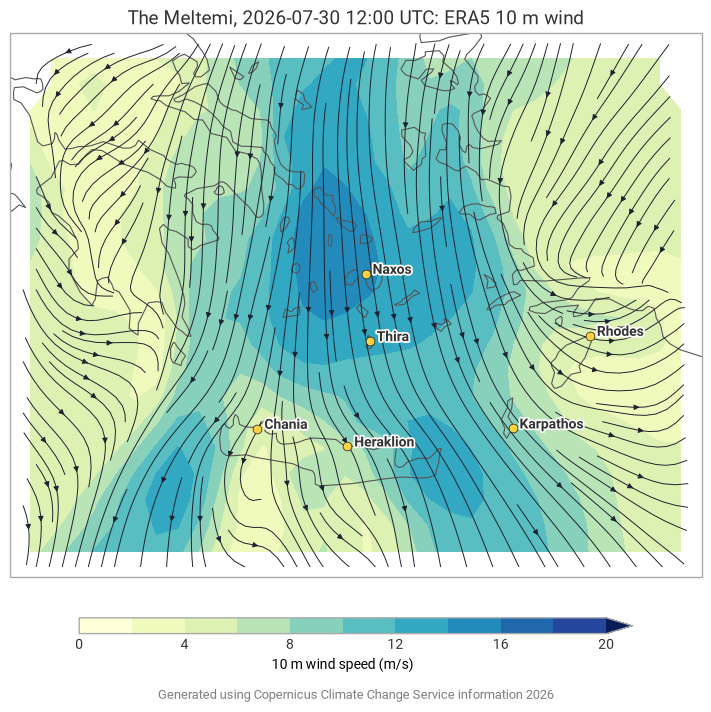

In [6]:
u, v, s = ds["10u"].sel(valid_time=HOUR), ds["10v"].sel(valid_time=HOUR), speed.sel(valid_time=HOUR)
style = ekp.styles.Style(levels=[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20], colors="YlGnBu", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]])
chart.contourf(s, style=style)
chart.ax.streamplot(u.longitude.values, u.latitude.values, u.values, v.values, color="#1d2230", density=1.8,
                    linewidth=0.7, arrowsize=0.8, transform=ccrs.PlateCarree(), zorder=5)
chart.coastlines(linewidth=0.8); chart.borders(linewidth=0.6)
for name, la, lo in PLACES:
    chart.scatter(x=[lo], y=[la], s=40, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
    chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label="10 m wind speed (m/s)")
chart.title(f"The Meltemi, {HOUR.replace('T', ' ')} UTC: ERA5 10 m wind", fontsize=14)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("meltemi_era5.png")
chart.show()

## 4 · How the wind changed through the three days

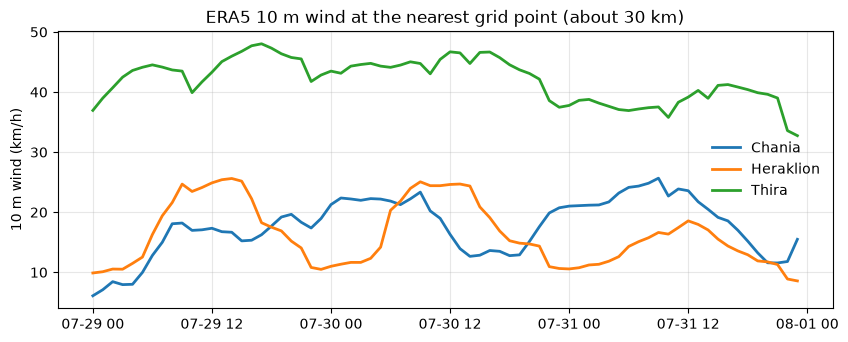

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, la, lo in PLACES[:3]:
    p = speed.sel(latitude=la, longitude=lo, method="nearest")
    ax.plot(p.valid_time, p * 3.6, label=name, lw=2)
ax.set_ylabel("10 m wind (km/h)"); ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.set_title("ERA5 10 m wind at the nearest grid point (about 30 km)")
plt.show()

## 5 · Your turn 🌍

- **Another Meltemi:** try `DAYS = ["2026-08-14", "2026-08-15", "2026-08-16"]`, or any July or August since 1940.
- **Gusts:** add `"instantaneous_10m_wind_gust"` to the variables; it is named `i10fg`.
- **Sharper detail:** ERA5 runs at about 31 km, so it smooths the gaps between the islands and the lee of Crete.
  ECMWF's 9 km forecasts (free as open data for the latest days) show those much more clearly.

### Data & licence
ERA5 is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Climate Change
Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels) ·
[earthkit](https://earthkit.ecmwf.int)